# TA-04: Peramalan Suhu Rata-Rata Harian di Kota Delhi Menggunakan LSTM

Dataset: [Daily Weather Time Series Data - Delhi, India (Kaggle)](https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india), April 2013 sampai November 2024.

**Persiapan:** unduh dataset dari Kaggle, ekstrak, lalu letakkan file CSV-nya di folder `data/` (di Google Colab: buat folder `data` dan upload file CSV ke sana). Boleh satu file atau beberapa file; semua CSV di `data/` digabung.

Alur: muat data → EDA → pembersihan → split kronologis → scaling → windowing → model LSTM → evaluasi → simpan model dan scaler.

In [6]:
# Khusus Google Colab / Jupyter: samakan versi scikit-learn dengan requirements.txt (kompatibel Python 3.9-3.13)
!pip install -q scikit-learn==1.6.1

In [7]:
import os, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATA_DIR = "data"
MODEL_DIR = "model"
os.makedirs(DATA_DIR, exist_ok=True)
TARGET = "meantemp"      # nama kolom suhu di dalam program (dipakai juga oleh aplikasi Flask)
DATE_COL = None          # isi manual jika kolom tanggal tidak terdeteksi otomatis, mis. "date"
TEMP_COL = None          # isi manual jika kolom suhu rata-rata tidak terdeteksi, mis. "temperature_2m_mean"

TIMESTEPS = 30          # pakai 30 hari terakhir untuk memprediksi hari ke-31
os.makedirs(MODEL_DIR, exist_ok=True)

## 1. Memuat Data
Semua CSV di folder `data/` digabung. Kolom tanggal dan kolom suhu rata-rata dideteksi otomatis dari nama kolomnya; jika dataset hanya punya suhu maksimum dan minimum, suhu rata-rata dihitung dari keduanya. Tanggal ganda dibuang.

In [8]:
import glob

files = [f for f in sorted(glob.glob(f"{DATA_DIR}/*.csv")) if not f.endswith("delhi_climate_clean.csv")]
assert files, "Taruh file CSV dataset Kaggle di folder data/ terlebih dahulu."
raw = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
print("File  :", files)
print("Kolom :", list(raw.columns))

cols = {c.lower().strip(): c for c in raw.columns}
def pick(*names):
    return next((cols[n] for n in names if n in cols), None)

date_col = DATE_COL or pick("date", "datetime", "time", "day", "tanggal")
temp_col = TEMP_COL or pick("meantemp", "temp", "temperature", "tavg", "temp_mean", "mean_temp", "avg_temp",
                            "temperature_mean", "temperature_2m_mean", "average_temperature")
if date_col is None:
    raise ValueError(f"Kolom tanggal tidak dikenali. Isi DATE_COL di sel pengaturan. Kolom tersedia: {list(raw.columns)}")
if temp_col is not None:
    raw[TARGET] = pd.to_numeric(raw[temp_col], errors="coerce")
else:
    tmax = pick("tmax", "temp_max", "max_temp", "maxtemp", "temperature_2m_max", "temperature_max")
    tmin = pick("tmin", "temp_min", "min_temp", "mintemp", "temperature_2m_min", "temperature_min")
    if not (tmax and tmin):
        raise ValueError(f"Kolom suhu tidak dikenali. Isi TEMP_COL di sel pengaturan. Kolom tersedia: {list(raw.columns)}")
    raw[TARGET] = (pd.to_numeric(raw[tmax], errors="coerce") + pd.to_numeric(raw[tmin], errors="coerce")) / 2
print(f"Tanggal: '{date_col}' | Suhu: '{temp_col or (tmax + ' & ' + tmin)}'")

raw["date"] = pd.to_datetime(raw[date_col], errors="coerce", utc=True).dt.tz_localize(None).dt.normalize()
df = raw.dropna(subset=["date"]).groupby("date")[[TARGET]].mean().sort_index()
if df[TARGET].median() > 100:      # jaga-jaga jika satuan Kelvin
    df[TARGET] = df[TARGET] - 273.15

print("Ukuran data:", df.shape)
print("Rentang   :", df.index.min().date(), "sampai", df.index.max().date())
df.head()

File  : ['data/kaggel_weather_2013_to_2024.csv']
Kolom : ['Unnamed: 0', 'DATE', 'tempmax', 'tempmin', 'temp', 'feelslikemax', 'feelslikemin', 'feelslike', 'humidity', 'precip', 'precipprob', 'precipcover', 'windspeed', 'sealevelpressure', 'conditions', 'Year', 'month', 'dayofweek', 'dayofyear', 'year-2000', 'weekofyear', 'tempmax_humidity', 'tempmin_humidity', 'temp_humidity', 'feelslikemax_humidity', 'feelslikemin_humidity', 'feelslike_humidity', 'temp_range', 'heat_index']
Tanggal: 'DATE' | Suhu: 'temp'
Ukuran data: (3556, 1)
Rentang   : 2013-04-14 sampai 2024-11-30


,meantemp
date,
2013-04-14,28.7
2013-04-15,28.6
2013-04-16,31.7
2013-04-17,29.9
2013-04-18,30.6


## 2. Pembersihan Data
Cek tanggal yang hilang, nilai kosong, dan pastikan frekuensi data harian lengkap.

In [9]:
full_range = pd.date_range(df.index.min(), df.index.max(), freq="D")
print("Tanggal hilang :", len(full_range.difference(df.index)))
print("Nilai kosong   :\n", df.isnull().sum())

# Lengkapi tanggal yang hilang (jika ada) dan isi dengan interpolasi berbasis waktu
df = df.reindex(full_range)
df.index.name = "date"
df[TARGET] = df[TARGET].interpolate(method="time")
print("Sisa nilai kosong pada target:", df[TARGET].isnull().sum())
df.describe()

Tanggal hilang : 693
Nilai kosong   :
 meantemp    0
dtype: int64
Sisa nilai kosong pada target: 0


,meantemp
count,4249.000000
mean,25.431466
std,7.228744
min,6.500000
25%,19.100000
50%,27.853846
75%,31.007692
max,39.500000


## 3. Eksplorasi Data (EDA): tren dan musiman

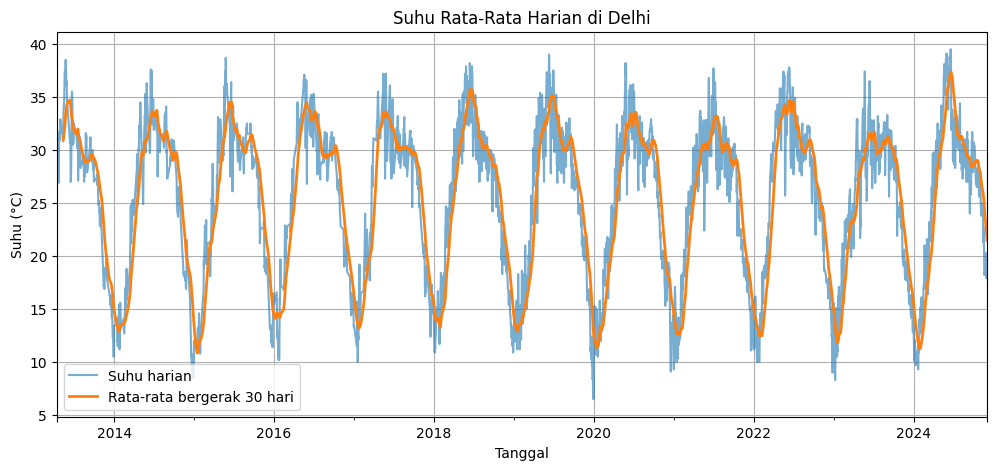

In [10]:
fig, ax = plt.subplots(figsize=(12, 5))
df[TARGET].plot(ax=ax, label="Suhu harian", alpha=0.6)
df[TARGET].rolling(30).mean().plot(ax=ax, label="Rata-rata bergerak 30 hari", linewidth=2)
ax.set_title("Suhu Rata-Rata Harian di Delhi")
ax.set_xlabel("Tanggal"); ax.set_ylabel("Suhu (°C)")
ax.grid(True); ax.legend()
plt.show()

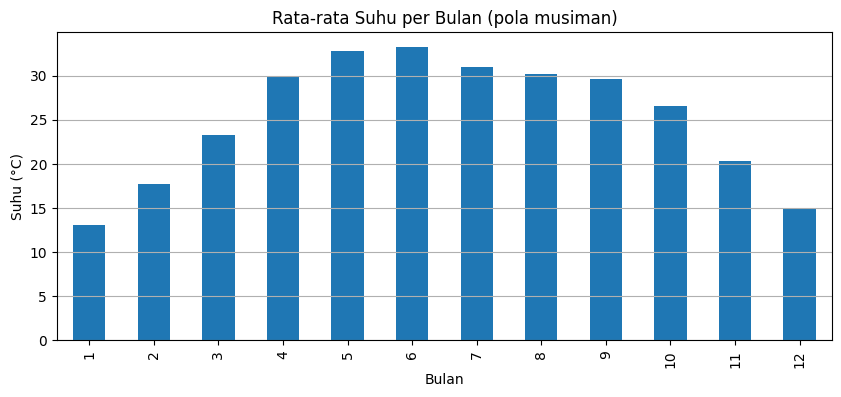

In [11]:
monthly = df.groupby(df.index.month)[TARGET].mean()
fig, ax = plt.subplots(figsize=(10, 4))
monthly.plot(kind="bar", ax=ax)
ax.set_title("Rata-rata Suhu per Bulan (pola musiman)")
ax.set_xlabel("Bulan"); ax.set_ylabel("Suhu (°C)")
ax.grid(True, axis="y")
plt.show()

**Catatan EDA (isi sesuai pengamatanmu):** suhu menunjukkan pola musiman tahunan yang jelas (rendah di Des-Jan, tinggi di Mei-Jun) tanpa tren naik/turun yang kuat dalam rentang data ini.

## 4. Split Kronologis, Scaling, dan Windowing
Data deret waktu **tidak boleh diacak**. Split dilakukan berurutan: 70% latih, 15% validasi, 15% uji. `MinMaxScaler` hanya di-*fit* pada data latih agar tidak ada kebocoran informasi (data leakage).

In [12]:
values = df[[TARGET]].values.astype("float32")
n = len(values)
n_train = int(n * 0.70)
n_val = int(n * 0.15)

scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(values[:n_train])            # fit hanya pada data latih
scaled = scaler.transform(values)

def make_sequences(data, start, end, timesteps):
    """Untuk setiap indeks i: input = timesteps hari sebelum i, target = nilai hari i."""
    X, y = [], []
    for i in range(start, end):
        X.append(data[i - timesteps:i, 0])
        y.append(data[i, 0])
    X = np.array(X).reshape(-1, timesteps, 1)   # (samples, timesteps, features)
    return X, np.array(y)

X_train, y_train = make_sequences(scaled, TIMESTEPS, n_train, TIMESTEPS)
X_val,   y_val   = make_sequences(scaled, n_train, n_train + n_val, TIMESTEPS)
X_test,  y_test  = make_sequences(scaled, n_train + n_val, n, TIMESTEPS)
test_dates = df.index[n_train + n_val:]

print("X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test:", X_test.shape)

X_train: (2944, 30, 1) | X_val: (637, 30, 1) | X_test: (638, 30, 1)


## 5. Membangun Model LSTM

In [13]:
# [TF]
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.random.set_seed(SEED)

model = Sequential([
    Input(shape=(TIMESTEPS, 1)),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1),
])
model.compile(optimizer="adam", loss="mean_squared_error")
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Melatih Model
`EarlyStopping` menghentikan pelatihan jika `val_loss` tidak membaik selama 10 epoch dan mengembalikan bobot terbaik.

In [14]:
early_stop = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[early_stop],
    verbose=1,
)

Epoch 1/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 14s 73ms/step - loss: 0.0368 - val_loss: 0.0057
Epoch 2/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - loss: 0.0095 - val_loss: 0.0057
Epoch 3/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - loss: 0.0080 - val_loss: 0.0059
Epoch 4/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 0.0067 - val_loss: 0.0043
Epoch 5/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - loss: 0.0063 - val_loss: 0.0051
Epoch 6/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - loss: 0.0057 - val_loss: 0.0040
Epoch 7/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - loss: 0.0055 - val_loss: 0.0039
Epoch 8/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 0.0049 - val_loss: 0.0038
Epoch 9/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 0.0047 - val_loss: 0.0036
Epoch 10/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - loss: 0.0045 - val_loss: 0.0043
Epoch 11/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 0.0043 - val_loss: 0.0035
Epoch 12/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/ste

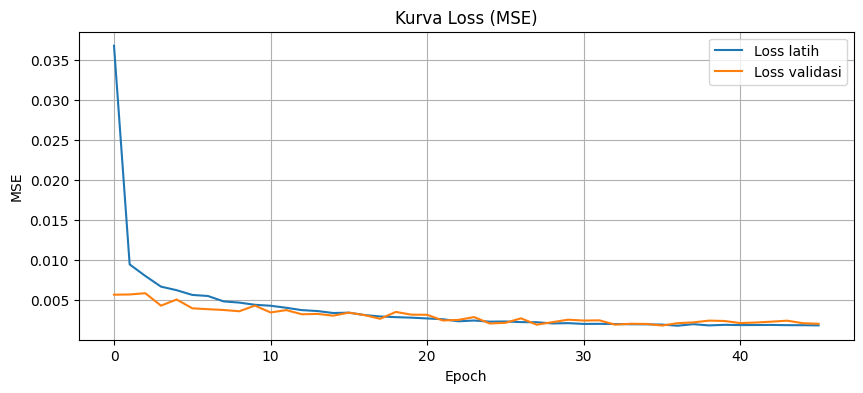

In [15]:
plt.figure(figsize=(10, 4))
plt.plot(history.history["loss"], label="Loss latih")
plt.plot(history.history["val_loss"], label="Loss validasi")
plt.title("Kurva Loss (MSE)")
plt.xlabel("Epoch"); plt.ylabel("MSE")
plt.legend(); plt.grid(True)
plt.show()

## 7. Evaluasi pada Data Uji
Prediksi dan nilai aktual dikembalikan ke skala asli (°C) dengan `inverse_transform`. Sebagai pembanding, dipakai baseline sederhana: *suhu hari ini = suhu kemarin*.

In [16]:
pred_scaled = model.predict(X_test, verbose=0)
y_pred = scaler.inverse_transform(pred_scaled).ravel()
y_true = scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()

rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
mae = float(mean_absolute_error(y_true, y_pred))

# Baseline: prediksi = nilai hari sebelumnya
y_naive = values[n_train + n_val - 1:n - 1, 0]
naive_rmse = float(np.sqrt(mean_squared_error(y_true, y_naive)))
naive_mae = float(mean_absolute_error(y_true, y_naive))

print(f"LSTM     -> RMSE: {rmse:.2f} °C | MAE: {mae:.2f} °C")
print(f"Baseline -> RMSE: {naive_rmse:.2f} °C | MAE: {naive_mae:.2f} °C")

LSTM     -> RMSE: 1.45 °C | MAE: 1.14 °C
Baseline -> RMSE: 1.31 °C | MAE: 0.99 °C


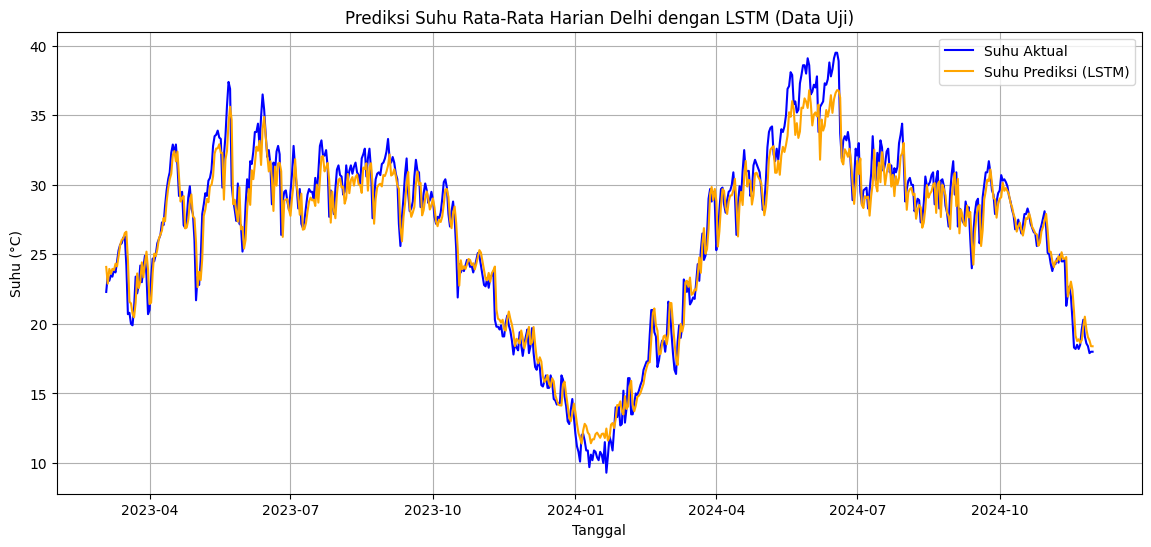

In [17]:
plt.figure(figsize=(14, 6))
plt.plot(test_dates, y_true, label="Suhu Aktual", color="blue")
plt.plot(test_dates, y_pred, label="Suhu Prediksi (LSTM)", color="orange")
plt.title("Prediksi Suhu Rata-Rata Harian Delhi dengan LSTM (Data Uji)")
plt.xlabel("Tanggal"); plt.ylabel("Suhu (°C)")
plt.legend(); plt.grid(True)
plt.show()

## 8. Contoh Peramalan 7 Hari ke Depan (rekursif)
Logika yang sama dipakai oleh aplikasi Flask.

In [18]:
window = scaled[-TIMESTEPS:].reshape(1, TIMESTEPS, 1).astype("float32")
preds = []
for _ in range(7):
    p = float(model.predict(window, verbose=0)[0, 0])
    preds.append(p)
    window = np.concatenate([window[:, 1:, :], np.array(p, dtype="float32").reshape(1, 1, 1)], axis=1)

future = scaler.inverse_transform(np.array(preds).reshape(-1, 1)).ravel()
future_dates = pd.date_range(df.index[-1] + pd.Timedelta(days=1), periods=7)
pd.DataFrame({"tanggal": future_dates.date, "suhu_prediksi_C": future.round(2)})

,tanggal,suhu_prediksi_C
0,2024-12-01,18.37
1,2024-12-02,18.63
2,2024-12-03,18.87
3,2024-12-04,19.09
4,2024-12-05,19.31
5,2024-12-06,19.53
6,2024-12-07,19.77


## 9. Menyimpan Model, Scaler, dan Data untuk Aplikasi Flask

In [19]:
model.save(f"{MODEL_DIR}/lstm_model.h5")
joblib.dump(scaler, f"{MODEL_DIR}/scaler.pkl")

# Data bersih yang dipakai aplikasi untuk menampilkan riwayat dan sebagai input peramalan
df[[TARGET]].round(4).to_csv(f"{DATA_DIR}/delhi_climate_clean.csv", index_label="date")

with open(f"{MODEL_DIR}/config.json", "w") as f:
    json.dump({"timesteps": TIMESTEPS, "target": TARGET}, f, indent=2)

metrics = {
    "rmse": round(rmse, 4), "mae": round(mae, 4),
    "naive_rmse": round(naive_rmse, 4), "naive_mae": round(naive_mae, 4),
    "epochs_trained": len(history.history["loss"]),
    "n_train": int(len(X_train)), "n_val": int(len(X_val)), "n_test": int(len(X_test)),
    "test_dates": [d.strftime("%Y-%m-%d") for d in test_dates],
    "test_actual": [round(float(v), 2) for v in y_true],
    "test_pred": [round(float(v), 2) for v in y_pred],
}
with open(f"{MODEL_DIR}/metrics.json", "w") as f:
    json.dump(metrics, f)

print("Tersimpan di folder model/ dan data/delhi_climate_clean.csv")
print("scikit-learn:", sklearn.__version__, "| tensorflow:", tf.__version__)
print("Samakan versi scikit-learn di requirements.txt dengan versi di atas.")

Tersimpan di folder model/ dan data/delhi_climate_clean.csv
scikit-learn: 1.6.1 | tensorflow: 2.21.0
Samakan versi scikit-learn di requirements.txt dengan versi di atas.
